### 1.FETCHING SENTINEL-2 DATA

In [ ]:
import pystac_client
import planetary_computer
import rioxarray
import matplotlib.pyplot as plt
import numpy as np

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

time_range = "2023-10-01/2023-10-31"
bbox = [6.40, 9.40, 6.70, 9.80]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime=time_range,
    query={"eo:cloud_cover": {"lt": 50}},
)
items = list(search.items()) 

# Score each scene by actual AOI cloud cover
invalid_classes = [0, 1, 3, 8, 9, 10]
for stac_item in items:
    scl = rioxarray.open_rasterio(stac_item.assets["SCL"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
    local_cloud_pct = np.isin(scl.values, invalid_classes).sum() / scl.values.size * 100
    stac_item.properties["local_aoi_cloud_cover"] = local_cloud_pct

if items:
    item = min(items, key=lambda x: x.properties["local_aoi_cloud_cover"])

    print("\n--- SELECTED SCENE ---")
    print(f"ID          : {item.id}")
    print(f"Date        : {item.properties['datetime']}")
    print(f"Global cloud: {item.properties['eo:cloud_cover']:.1f}%")
    print(f"AOI cloud   : {item.properties['local_aoi_cloud_cover']:.1f}%")
    print(f"Baseline    : {item.properties.get('s2:processing_baseline')}")
else:
    print("No items found. Adjust search parameters.")


--- SELECTED SCENE ---
ID          : S2B_MSIL2A_20231029T095029_R079_T31PHL_20231029T142618
Date        : 2023-10-29T09:50:29.024000Z
Global cloud: 45.3%
AOI cloud   : 32.4%
Baseline    : 05.09


#### CLOUD COVER SUMMARY FOR THE SELECTED SCENE
The initial query applied a global scene-level cloud cover threshold of <20%, which returned no valid scenes for the specified bounding box and October 2023 time window. Hence, a key limitation of scene-level cloud metadata: a globally clear scene can still be heavily clouded over a specific area of interest, and vice versa.  
To address this, the scene selection approach was revised. Rather than relying on the global eo:cloud_cover metadata, the SCL (Scene Classification Layer) was loaded and clipped to the exact bounding box for every candidate scene. Cloud and invalid pixels (SCL classes 0, 1, 3, 8, 9, 10) were then counted directly within the AOI to compute a local cloud cover percentage. Applying this pixel-level approach across all October 2023 scenes revealed a notable discrepancy between global and local cloud cover. The selected scene:
- **Scene ID**: S2B_MSIL2A_20231029T095029_R079_T31PHL_20231029T142618  
- **Date**: 29 October 2023  
- **Global scene cloud cover**: 45.3%  
- **Local AOI cloud cover**: 32.4%  

This scene would have been excluded under the original <20% global threshold, yet it represents the least cloudy observation over the study area in the entire month. It was therefore selected as the best available scene for analysis, balancing temporal relevance with atmospheric conditions over the AOI.

### 2. LOADING SPECTRAL BANDS

In [3]:
import rioxarray 
from rasterio.enums import Resampling

b8a = rioxarray.open_rasterio(item.assets["B8A"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b11 = rioxarray.open_rasterio(item.assets["B11"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b12 = rioxarray.open_rasterio(item.assets["B12"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()

b02 = rioxarray.open_rasterio(item.assets["B02"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b02_20m = b02.rio.reproject_match(b8a, resampling=Resampling.average)

b04 = rioxarray.open_rasterio(item.assets["B04"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b04_20m = b04.rio.reproject_match(b8a, resampling=Resampling.average)


### 3. CLOUD MASKING AND APPLYING RADIOMETRIC OFFSET & REFLECTANCE

In [5]:

radiometric_offset = item.properties.get("s2:radiometric_offset", -1000)
scale_factor = 0.0001 

# Building the mask from SCL
scl = rioxarray.open_rasterio(item.assets["SCL"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
invalid_classes = [0, 1, 3, 8, 9, 10]
mask = np.isin(scl.values, invalid_classes)

# Converting to float32 and applying radiometric offset + scale factor
b02_float = ((b02_20m.values.astype(np.float32) + radiometric_offset) * scale_factor).clip(min=0)
b04_float = ((b04_20m.values.astype(np.float32)+ radiometric_offset) * scale_factor).clip(min=0)
b8a_float = ((b8a.values.astype(np.float32)+ radiometric_offset) * scale_factor).clip(min=0)
b11_float = ((b11.values.astype(np.float32)+ radiometric_offset) * scale_factor).clip(min=0)
b12_float = ((b12.values.astype(np.float32)+ radiometric_offset) * scale_factor).clip(min=0)

# Applying mask and setting the invalid pixels to NaN
b02_float[mask] = np.nan
b04_float[mask] = np.nan
b8a_float[mask] = np.nan
b11_float[mask] = np.nan
b12_float[mask] = np.nan

# Valid pixels
b02_masked = b02_float
b04_masked = b04_float
b8a_masked = b8a_float
b11_masked = b11_float
b12_masked = b12_float


### 4. SURFACE REFLECTANCE AND INDEX COMPUTATION

In [6]:

# Surface reflectance
albedo = (0.356*b02_masked + 0.130*b04_masked + 0.373*b8a_masked 
          + 0.085*b11_masked + 0.072*b12_masked - 0.0018)
albedo = np.clip(albedo, 0, 1)

# Index computation
ndvi = (b8a_masked - b04_masked) / (b8a_masked + b04_masked)

# Computing mean and standard deviation for the indices
albedo_mean = float(np.nanmean(albedo))
albedo_std = float(np.nanstd(albedo))
ndvi_mean   = float(np.nanmean(ndvi))
ndvi_std =  float(np.nanstd(ndvi))

print(f"Albedo-mean: {albedo_mean:.4f}")
print(f"Albedo-std: {albedo_std:.4f}")
print(f"NDVI-mean:   {ndvi_mean:.4f}")
print(f"NDVI-std:   {ndvi_std:.4f}")


Albedo-mean: 0.2166
Albedo-std: 0.0371
NDVI-mean:   0.5748
NDVI-std:   0.1688


##### INDICES INTERPRETATION
- NDVI mean	of 0.5748 suggests a moderate to healthy vegetation.
- Albedo standard deviation of 0.0371 suggests very low spread, spatially homogeneous surface.

### 5.VISUALIZATION

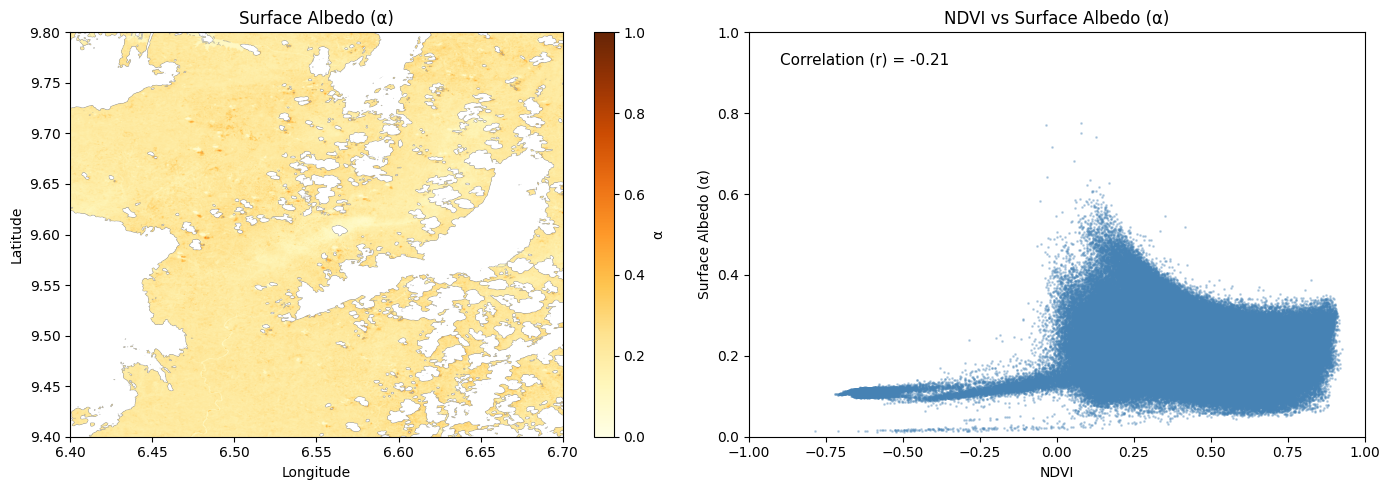

In [8]:

# Creating a valid data mask
valid = ~np.isnan(albedo) & ~np.isnan(ndvi)
albedo_valid = albedo[valid]
ndvi_valid   = ndvi[valid]

corr = np.corrcoef(ndvi_valid, albedo_valid)[0, 1]

# Plot
left, bottom, right, top = bbox[0], bbox[1], bbox[2], bbox[3]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left Spatial map of albedo
im = ax1.imshow(albedo, cmap="YlOrBr", vmin=0, vmax=1, extent=[left, right, bottom, top], aspect="auto")
ax1.set_title("Surface Albedo (α)")
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")
plt.colorbar(im, ax=ax1, label="α")

# Right Scatter plot NDVI vs Albedo
ax2.scatter(ndvi_valid, albedo_valid, s=1, alpha=0.3, color="steelblue")
ax2.set_title("NDVI vs Surface Albedo (α)")
ax2.set_xlabel("NDVI")
ax2.set_ylabel("Surface Albedo (α)")
ax2.set_xlim(-1, 1)
ax2.set_ylim(0, 1)
ax2.text(0.05, 0.95, f"Correlation (r) = {corr:.2f}",
         transform=ax2.transAxes,
         fontsize=11,
         verticalalignment='top')

plt.tight_layout()
plt.savefig("../outputs/albedo_ndvi_plot.png", dpi=150, bbox_inches="tight")
plt.show()


### 6. RESULTS INTERPRETATION
- The correlation of -0.21 suggests a weak to moderate negative relationship with consistent that higher vegetation density is associated with lower albedo. 
- The fan shape scatterplot suggests:  
    -Low NDVI (-0.75 to 0): water, cloud shadows, bare soil and a wide spread of albedo values.  
    -NDVI 0 to 0.5: transition zone.  
    -High NDVI (>0.5): dense vegetation, albedo converges and slightly decreases suggesting a canopy absorption.
